# Supply API Quick Start

## Run this example in [Colab](https://colab.research.google.com/github/SignalOceanSdk/SignalSDK/blob/master/docs/examples/jupyter/SupplyAPI/QuickStartSupplyAPI.ipynb)

The Supply API tells you which vessels are available for a market segment, and how many. This notebook calls its three methods with the same filters:

- `get_supply_trend`: vessel counts per day for a date range.
- `get_historical_supply`: the vessels of one past day.
- `get_live_supply`: the vessels now.

## Setup
Install the Signal Ocean SDK:
```
pip install signal-ocean
```
You need your own API key with access to the Supply API, for the vessel classes that you query. Get your key here: https://apis.signalocean.com/profile

In [ ]:
!pip install signal-ocean

In [2]:
signal_ocean_api_key = ''  # Replace with your subscription key

In [3]:
from datetime import date

from signal_ocean import Connection
from signal_ocean.supply import (
    AvailabilityState,
    CommercialAvailabilityFilter,
    SupplyAPI,
    SupplyFilter,
    VesselClass,
)

connection = Connection(signal_ocean_api_key)
api = SupplyAPI(connection)

## Filters
Every request needs a vessel class, or a size band. Here we ask for Aframax tankers that are commercially available.

In [4]:
filters = SupplyFilter(
    vessel_class=VesselClass.AFRAMAX,
    commercial_availability=CommercialAvailabilityFilter(
        availability_state=[AvailabilityState.AVAILABLE]
    ),
)

## Supply trend
`get_supply_trend` counts the matching vessels on each day. Commercial availability history starts on 29 January 2026, so the range starts after that day.

In [5]:
trend = api.get_supply_trend(date(2026, 8, 1), date(2026, 10, 31), filters=filters)
trend_frame = trend.to_data_frame()
trend_frame.tail()

,supply
date,
2026-10-27,1087
2026-10-28,1093
2026-10-29,1103
2026-10-30,1115
2026-10-31,1115


<Axes: title={'center': 'Available Aframax tankers per day'}, ylabel='Vessels'>

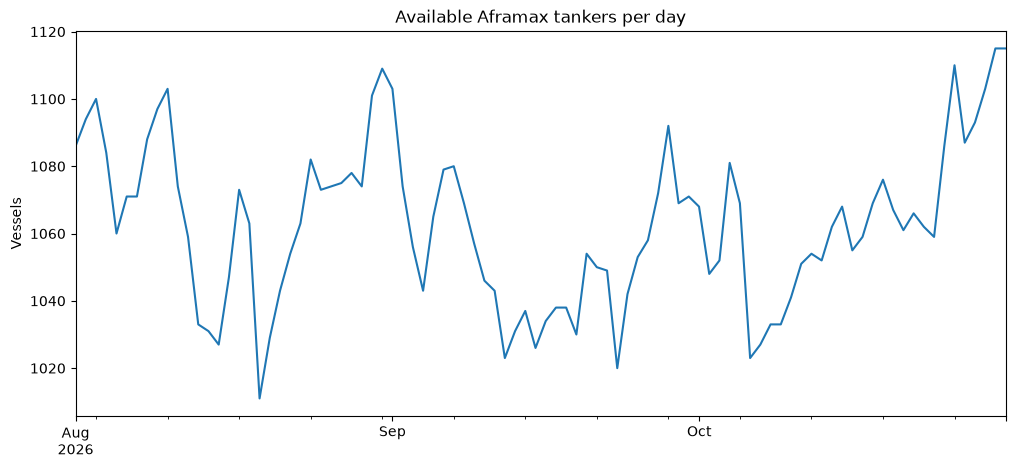

In [6]:
trend_frame.plot(y="supply", figsize=(12, 5), legend=False,
    title="Available Aframax tankers per day", ylabel="Vessels", xlabel="")

## Vessels of one past day
`get_historical_supply` returns one record per vessel. Each API key can make 5 of these calls per day, so use the trend for counts over a range.

In [7]:
day = api.get_historical_supply(date(2026, 10, 15), filters=filters)
day_frame = day.to_data_frame()
print(f"{len(day_frame)} vessels")
day_frame[["imo", "open_location", "open_date_to", "availability_state", "voyage_state", "ais_current_area"]].head(10)

1068 vessels


,imo,open_location,open_date_to,availability_state,voyage_state,ais_current_area
0,1095088,Barcelona,2026-11-02 19:41:48.463,Available,Laden,Arabian Gulf
1,9855496,Arabian Gulf,2026-08-21 10:24:11.000,Available,BallastUnfixed,Arabian Gulf
2,9855367,Las Palmas,2026-10-20 13:18:07.519,Available,Laden,West Mediterranean
3,9229362,Tanjung Pelepas,2026-08-01 20:04:24.716,Available,WaitToDischarge,Singapore / Malaysia
4,9229350,Ningbo,2026-10-22 07:03:08.088,Available,Laden,Philippines
5,9384992,Vadinar,2026-10-15 23:59:59.000,Available,Discharging,Pakistan / West Coast India
6,9697600,Australia East,2026-10-15 11:37:45.000,Available,BallastUnfixed,Australia East
7,9697595,Singapore / Malaysia,2026-10-15 11:37:30.000,Available,BallastUnfixed,Singapore / Malaysia
8,9071806,NaN,NaT,NaN,NaN,Thailand / Vietnam
9,1093444,Jinhai Heavy Industries Port,2026-11-20 00:00:00.000,Available,Repairs,Central China


## Live supply
`get_live_supply` returns the same kind of records for now.

In [8]:
live = api.get_live_supply(filters=filters)
live_frame = live.to_data_frame()
print(f"{len(live_frame)} vessels")
live_frame[["imo", "open_location", "open_date_to", "availability_state", "voyage_state", "ais_current_area"]].head(10)

1043 vessels


,imo,open_location,open_date_to,availability_state,voyage_state,ais_current_area
0,9389277,Ningbo,2026-11-25 23:59:59.000+00:00,Available,Laden,Alaska
1,9290294,Arabian Gulf,2026-11-11 14:09:00.000+00:00,Available,BallastUnfixed,East Africa
2,1021790,Chiba,2026-12-10 01:43:57.018+00:00,Available,Laden,Red Sea
3,9708150,Caribs,2026-11-11 14:09:33.000+00:00,Available,BallastUnfixed,US Atlantic Coast
4,1059644,New York,2026-11-26 23:59:59.000+00:00,Available,Laden,Iberian Atlantic Coast
5,9422550,Laem Chabang,2026-11-11 23:59:59.000+00:00,Available,Repairs,Thailand / Vietnam
6,9394947,Singapore,2026-11-20 23:59:59.000+00:00,Available,Laden,East Coast India
7,9389095,Vadinar,2026-11-12 23:59:59.000+00:00,Available,Discharging,Pakistan / West Coast India
8,9231901,Duqm,2026-12-04 12:22:57.217+00:00,Available,BallastFixed,Arabian Gulf
9,9412464,Brazil,2026-11-15 08:08:24.196+00:00,Available,Loading,Brazil


## Next steps
The other Supply API notebooks show open based, ETA based, AIS based and fleet based supply, and the Baltic route templates.

In [9]:
connection.close()